# Aula 8 – Agrupamento e identificação de padrões operacionais

## Versão do aluno

### Objetivo da aula
Aplicar o algoritmo **K-means** para identificar grupos de comportamento operacional em uma base de dados industrial.

### Instruções
Complete as células indicadas e registre suas interpretações ao longo da atividade.


## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para leitura da base, visualização, padronização e agrupamento.


In [1]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## 2. Leitura da base

Leia o arquivo `dados_aula8_kmeans_industrial.csv` e mostre as primeiras linhas.


In [2]:
# Complete aqui
df = pd.read_csv('dados_aula8_kmeans_industrial.csv')
df.head()

,id_registro,linha,turno,produto,vazao_l_min,pressao_bar,temperatura_c,vibracao_mm_s,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,abertura_valvula_pct,estado_operacional_referencia
0,REG_0001,Linha_C,Manhã,Base,122.980285,3.520386,42.788341,1.338362,18.467412,1.492479,1.950425,0,53.539009,Estavel
1,REG_0002,Linha_C,Manhã,Solvente,119.170414,3.703415,40.919981,1.062157,19.379465,1.614617,1.596653,2,43.449158,Estavel
2,REG_0003,Linha_A,Noite,Acido,123.886131,3.352569,40.650675,1.311664,17.902116,NaN,1.895365,1,45.259073,Estavel
3,REG_0004,Linha_A,Tarde,Base,129.138179,3.431191,42.607915,4.203438,18.361541,1.560486,2.059482,1,55.716320,Estavel
4,REG_0005,Linha_B,Manhã,Acido,118.595080,3.417657,41.718437,1.105775,18.621130,1.436369,1.355104,0,52.854327,Estavel


## 3. Inspeção inicial

Verifique a dimensão da base, os tipos de dados, os valores faltantes e a quantidade de duplicatas.

**Registro técnico:**
- Quais colunas exigem tratamento?
- Há duplicatas?
- O que precisa ser ajustado antes de aplicar o K-means?


In [3]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:', df.duplicated().sum())

Dimensão da base: (270, 14)

Tipos de dados:
id_registro                       object
linha                             object
turno                             object
produto                           object
vazao_l_min                      float64
pressao_bar                      float64
temperatura_c                    float64
vibracao_mm_s                    float64
consumo_energia_kwh              float64
tempo_resposta_s                 float64
erro_vazao_pct                   float64
leituras_invalidas                 int64
abertura_valvula_pct             float64
estado_operacional_referencia     object
dtype: object

Valores faltantes:
id_registro                      0
linha                            0
turno                            0
produto                          9
vazao_l_min                      0
pressao_bar                      8
temperatura_c                    9
vibracao_mm_s                    0
consumo_energia_kwh              0
tempo_resposta_s                

**Registro do aluno:**

- 4 colunas exigem tratamento.
- Não há duplicatas.
- Fazer o tratamento dos valores faltantes.

## 4. Tratamento inicial

- Remova duplicatas.
- Trate valores faltantes numéricos com a mediana.
- Trate valores faltantes categóricos com a moda.


In [4]:
# Complete aqui
df = df.drop_duplicates().copy()

colunas_numericas = [
    'vazao_l_min', 'pressao_bar', 'temperatura_c', 'vibracao_mm_s',
    'consumo_energia_kwh', 'tempo_resposta_s', 'erro_vazao_pct',
    'leituras_invalidas', 'abertura_valvula_pct'
]

for col in colunas_numericas:
    df[col] = df[col].fillna(df[col].median())

for col in ['linha', 'turno', 'produto']:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isna().sum())

id_registro                      0
linha                            0
turno                            0
produto                          0
vazao_l_min                      0
pressao_bar                      0
temperatura_c                    0
vibracao_mm_s                    0
consumo_energia_kwh              0
tempo_resposta_s                 0
erro_vazao_pct                   0
leituras_invalidas               0
abertura_valvula_pct             0
estado_operacional_referencia    0
dtype: int64


## 5. Seleção das features

Monte a matriz `X` usando apenas as variáveis numéricas do processo.

**Pergunta:**  
Por que a coluna `estado_operacional_referencia` não deve ser usada como entrada do K-means?


In [5]:
# Complete aqui
X = df[colunas_numericas].copy()
X.head()

,vazao_l_min,pressao_bar,temperatura_c,vibracao_mm_s,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,abertura_valvula_pct
0,122.980285,3.520386,42.788341,1.338362,18.467412,1.492479,1.950425,0,53.539009
1,119.170414,3.703415,40.919981,1.062157,19.379465,1.614617,1.596653,2,43.449158
2,123.886131,3.352569,40.650675,1.311664,17.902116,2.277365,1.895365,1,45.259073
3,129.138179,3.431191,42.607915,4.203438,18.361541,1.560486,2.059482,1,55.716320
4,118.595080,3.417657,41.718437,1.105775,18.621130,1.436369,1.355104,0,52.854327


**Resposta do aluno:**
Caso a coluna seja usada como entrada, o algoritmo não iria aprender adequadamente como fazer previsões que chegariam nos valores da coluna `estado_operacional_referencia`.


## 6. Padronização

Padronize as variáveis com `StandardScaler`.

**Pergunta:**  
Por que a padronização é importante antes do K-means?


In [6]:
# Complete aqui
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[ 0.10124033, -0.02549359, -0.30541223, -0.9049264 , -0.67284053,
        -0.99293185, -1.13693772, -1.58258215,  0.00458417],
       [-0.07246552,  0.23781817, -0.56331686, -1.16114478, -0.44789565,
        -0.87500152, -1.33454717, -0.50490956, -0.81799044],
       [ 0.14254115, -0.26692127, -0.60049133, -0.92969297, -0.81226271,
        -0.23508793, -1.16769297, -1.04374586, -0.67043722],
       [ 0.3820011 , -0.15381293, -0.33031783,  1.75282832, -0.69895218,
        -0.92726794, -1.07602036, -1.04374586,  0.18208939],
       [-0.0986971 , -0.1732829 , -0.45309966, -1.1206831 , -0.63492825,
        -1.04710804, -1.4694712 , -1.58258215, -0.05123447]])

**Resposta do aluno:**
Caso as variáveis não estejam padronizadas, o algoritmo pode supor que as variáveis com valores mais altos são mais importantes que as outras.


## 7. Teste de valores de k

Calcule a inércia e o silhouette score para valores de `k` entre 2 e 7.


In [7]:
# Complete aqui
inercias = []
silhuetas = []
k_range = range(2, 8)

for k in k_range:
    modelo_temp = KMeans(n_clusters=k, random_state=42)
    grupos_temp = modelo_temp.fit_predict(X_scaled)
    inercias.append(modelo_temp.inertia_)
    silhuetas.append(silhouette_score(X_scaled, grupos_temp))

resultados_k = pd.DataFrame({
    'k': list(k_range),
    'inercia': inercias,
    'silhouette': silhuetas
})

resultados_k

,k,inercia,silhouette
0,2,1171.970379,0.535022
1,3,460.166777,0.660713
2,4,377.675108,0.669010
3,5,362.422042,0.634627
4,6,348.124050,0.632848
5,7,322.515056,0.496480


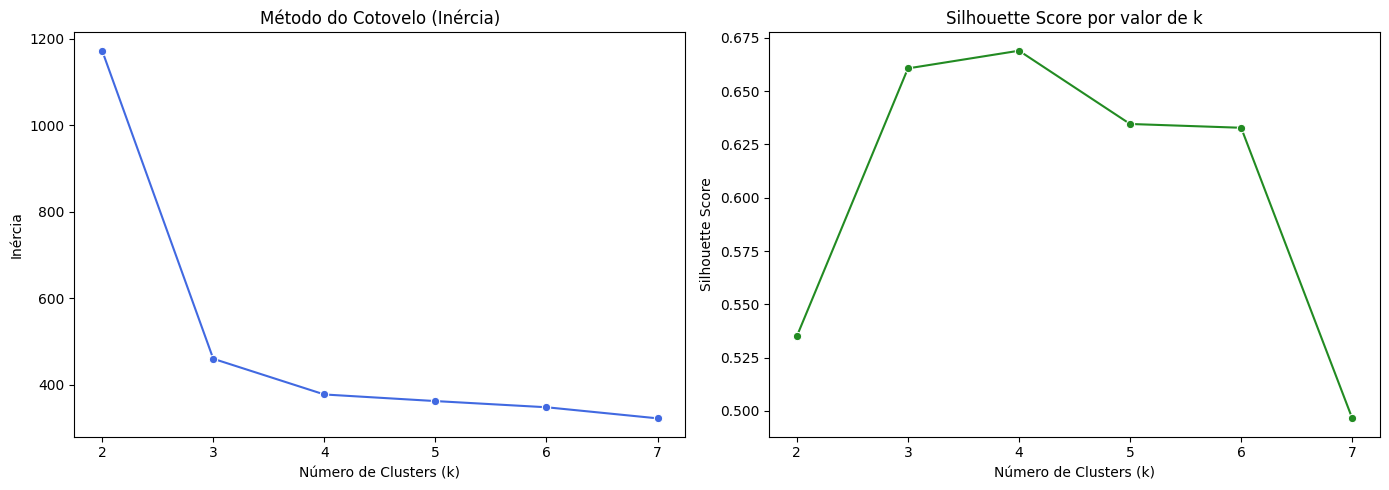

In [8]:
# Gere os gráficos aqui
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico da Inércia (Método do Cotovelo)
sns.lineplot(ax=axes[0], x='k', y='inercia', data=resultados_k, marker='o', color='royalblue')
axes[0].set_title('Método do Cotovelo (Inércia)')
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('Inércia')
axes[0].set_xticks(resultados_k['k'])

# Gráfico do Silhouette Score
sns.lineplot(ax=axes[1], x='k', y='silhouette', data=resultados_k, marker='o', color='forestgreen')
axes[1].set_title('Silhouette Score por valor de k')
axes[1].set_xlabel('Número de Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(resultados_k['k'])

plt.tight_layout()
plt.show()

## 8. Escolha do número de clusters

Escolha um valor de `k` e justifique sua decisão com base nos resultados.


**Justificativa do aluno:**
O valor escolhido foi o 4, pois é nele onde há uma estabilização no Método do Cotovelo e também o que mais se saiu bem no Silhouette Score.


## 9. Criação do modelo K-means

Crie o modelo com o valor de `k` escolhido, ajuste aos dados padronizados e gere os clusters.


In [9]:
# Complete aqui
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)
clusters = kmeans.labels_

df['cluster'] = clusters
df[['id_registro', 'cluster']].head()

,id_registro,cluster
0,REG_0001,2
1,REG_0002,2
2,REG_0003,2
3,REG_0004,2
4,REG_0005,2


## 10. Interpretação dos clusters

Calcule a média das variáveis numéricas por cluster e interprete o perfil de cada grupo.


In [10]:
# Complete aqui
perfil_clusters = df.groupby('cluster')[colunas_numericas].mean().round(2)
perfil_clusters

,vazao_l_min,pressao_bar,temperatura_c,vibracao_mm_s,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,abertura_valvula_pct
cluster,,,,,,,,,
0,146.93,4.34,54.50,2.25,25.30,2.37,4.28,3.04,67.84
1,94.85,2.73,38.39,3.52,20.34,3.76,6.04,4.94,40.14
2,119.41,3.51,41.96,1.27,18.05,1.53,1.83,1.00,51.95


**Interpretação do aluno:**
- Cluster 0: Maior vazão e abertura.
- Cluster 1: Maior erro de vazão, tempo de resposta e de leituras inválidas, possível degradação.
- Cluster 2: Estável, não apresenta valores alarmantes.


## 11. Visualização dos agrupamentos

Crie um gráfico de dispersão com duas variáveis importantes do processo e use a cor para distinguir os clusters.


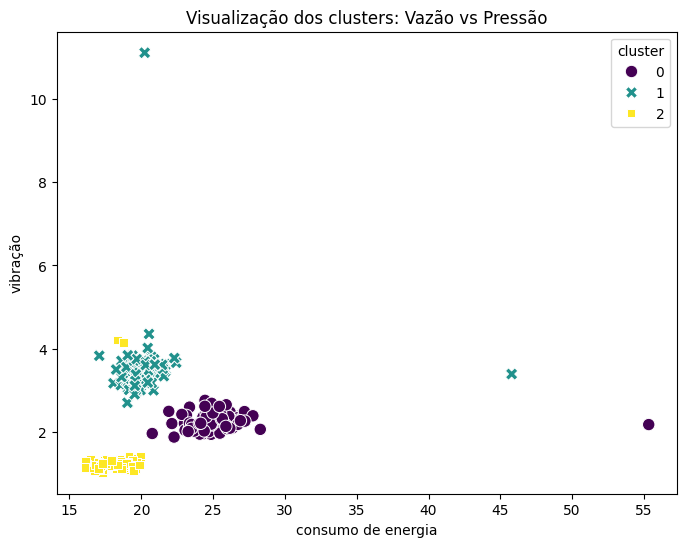

In [11]:
# Complete aqui
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='consumo_energia_kwh',
    y='vibracao_mm_s',
    hue='cluster',
    style='cluster',
    palette='viridis',
    s=80
)
plt.title('Visualização dos clusters: Vazão vs Pressão')
plt.xlabel('consumo de energia')
plt.ylabel('vibração')
plt.show()

## 12. Comparação com a coluna de referência

Monte uma tabela cruzada entre `cluster` e `estado_operacional_referencia`.

**Pergunta:**  
Os agrupamentos encontrados se aproximam de padrões operacionais reconhecíveis?


In [12]:
# Complete aqui
pd.crosstab(df['cluster'], df['estado_operacional_referencia'])

estado_operacional_referencia,Estavel,Instavel,Sobrecarga
cluster,,,
0,0,0,90
1,0,86,0
2,94,0,0


**Resposta do aluno:** Sim, mapeando perfeitamente o Estável, Instável e a Sobrecarga.



## 13. Não supervisionado x supervisionado

Explique, com suas palavras:
- o que caracteriza uma abordagem não supervisionada;
- como ela difere da supervisionada;
- como o agrupamento pode ajudar no contexto industrial.


**Resposta do aluno:**

- A abordagem não supervisionada é caracterizada pelo uso de algoritmos que trabalham com dados não rotulados, ou seja, dados que não possuem uma variável-alvo predefinida indicando a resposta correta.
- A supervisionada utiliza dados rotulados para treinar modelos preditivos, enquanto a não supervisionada opera sem rótulos com o objetivo de explorar e segmentar os dados por similaridade.
- Ajuda a identificar estados anômalos e desgastes mecânicos sem necessidade de histórico rotulado prévio.

## 14. Exportação da base final

Salve a base com a nova coluna `cluster`.


In [13]:
# Complete aqui
df.to_csv('dados_aula8_kmeans_industrial_resolvido.csv', index=False)
print('Arquivo exportado com sucesso.')

Arquivo exportado com sucesso.


## 15. Fechamento

Verifique se você:
- implementou corretamente o agrupamento;
- interpretou os padrões encontrados;
- registrou tecnicamente os resultados;
- organizou adequadamente os arquivos do experimento.
